# Figure 2: climate change during the AMOC recovery

Change in a) near-surface air temperature and b) precipitation: the 50-year mean centered on year 2600 minus the
50-year mean centered on year 2350. Those windows are years 2575-2624 and 2325-2374 since 8xCO2.

Inputs: `tas_ann_CESM104_abrupt8x_5100.nc`, `pr_mon_CESM104_abrupt8x_5100_g025.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common
import cartopy.crs as ccrs

matplotlib.rc('font', size=20)

YEAR_BEFORE, YEAR_AFTER = 2350, 2600   # centers of the two averaging windows [years since 8xCO2]
HALF_WINDOW = 25                       # each window is 2 * HALF_WINDOW = 50 years long
M_PER_S_TO_MM_PER_DAY = 1000 * 86400   # pr is stored in m/s
TAS_COLOR_LIMIT = 4                    # temperature color bar limit [degC]
PR_COLOR_LIMIT = 1.3                   # precipitation color bar limit [mm/day]

In [2]:
tas = xr.open_dataset(common.data_path('tas_ann_CESM104_abrupt8x_5100.nc')).tas
pr = xr.open_dataset(common.data_path('pr_mon_CESM104_abrupt8x_5100_g025.nc')).pr


def window_mean_tas(center_year):
    """Mean air temperature on (lat, lon) around center_year. The file is annual, so index i is year i since 8xCO2.

    Units are K, but only differences are used, so a change in K equals the same change in degC.
    """
    return tas.isel(time=slice(center_year - HALF_WINDOW, center_year + HALF_WINDOW)).mean(dim='time')


def window_mean_pr(center_year):
    """Mean precipitation [mm/day] on (lat, lon) around center_year. Monthly file; months count equally."""
    months = slice(12 * (center_year - HALF_WINDOW), 12 * (center_year + HALF_WINDOW))
    return pr.isel(time=months).mean(dim='time') * M_PER_S_TO_MM_PER_DAY


tas_diff = window_mean_tas(YEAR_AFTER) - window_mean_tas(YEAR_BEFORE)
pr_diff = window_mean_pr(YEAR_AFTER) - window_mean_pr(YEAR_BEFORE)

# Area-weighted (cos lat) global mean of the temperature change [degC]
tas_global_mean = float(tas_diff.weighted(np.cos(np.deg2rad(tas.lat))).mean(dim=('lat', 'lon')))
print(f'global mean temperature change: {tas_global_mean:.2f} degC')

global mean temperature change: 0.67 degC


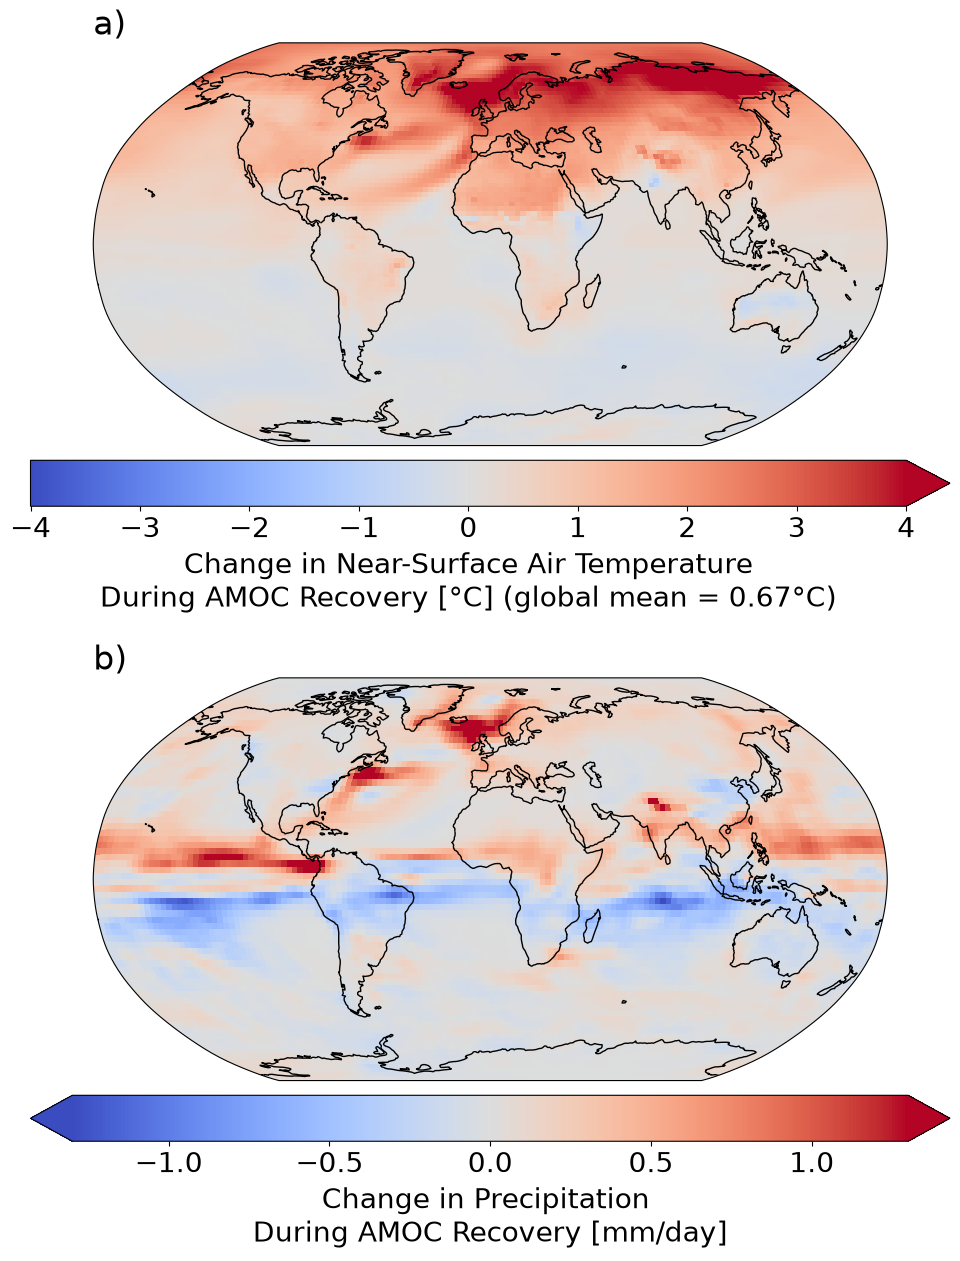

In [3]:
# Each panel: label, field, color bar limit, which ends of the color bar saturate, color bar label
panels = [
    ('a)', tas_diff, TAS_COLOR_LIMIT, 'max',
     f'Change in Near-Surface Air Temperature\nDuring AMOC Recovery [°C] (global mean = {tas_global_mean:.2f}°C)'),
    ('b)', pr_diff, PR_COLOR_LIMIT, 'both', 'Change in Precipitation \nDuring AMOC Recovery [mm/day]'),
]

fig, axes = plt.subplots(2, 1, figsize=(10, 13), subplot_kw={'projection': ccrs.Robinson()})
for ax, (panel_label, field, limit, saturates, colorbar_label) in zip(axes, panels):
    # transform tells cartopy the data are on a regular lon/lat grid, not in Robinson-projection meters
    p = ax.pcolormesh(field.lon, field.lat, field, cmap='coolwarm', vmax=limit, vmin=-limit, transform=ccrs.PlateCarree())
    ax.set_global()
    ax.coastlines()
    ax.set_title(panel_label, loc='left')
    fig.colorbar(p, ax=ax, extend=saturates, orientation='horizontal', pad=0.03, label=colorbar_label)

fig.tight_layout()
plt.savefig(common.figure_path('fig02_climate_impacts.png'), dpi=300, bbox_inches='tight')
plt.show()